<a href="https://colab.research.google.com/github/buiduytien-da/aeon-mall-sentiment-analysis-visobert/blob/main/sentiment_analysis_visobert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import re
import os

folder_path = '/content/drive/MyDrive/ColabNotebooks'
file_name = 'reviews cleaned.xlsx'
file_path = os.path.join(folder_path, file_name)

df = pd.read_excel(file_path)
df.columns = [col.strip().lower() for col in df.columns]
df.head()

,stars,reviews,islocalguide,reviewernumberofreviews,has_image,has_5_images_or_more,published_date,published_time
0,5,Trung tâm thương mại lớn .\nĐầy đủ mọi dịch vụ...,True,108,True,True,2025-06-13,02:17
1,5,☆ Ưu điểm:\n- Sức chứa khách lớn khủng khiếp\n...,True,66,True,True,2025-06-12,13:48
2,5,"Không gian rộng rãi, sang trọng, mát mẻ\nCó nh...",True,335,True,True,2025-08-02,14:59
3,5,"Cảnh quan bố trí hài hoà, không gian xanh, tạo...",True,63,True,True,2025-06-08,02:55
4,5,"Là 1 con dân Hà Đông, đã quen với Aeon xứ sư t...",True,247,True,True,2025-05-16,00:34


In [ ]:
# Bước 1: Thay emoji => token
emoji_map = {
    "😍": "<EMO_POS>", "😊": "<EMO_POS>", "❤️": "<EMO_POS>", "👍": "<EMO_POS>",
    "😡": "<EMO_NEG>", "😠": "<EMO_NEG>", "🤮": "<EMO_NEG>", "🥲": "<EMO_NEG>", "😭": "<EMO_NEG>"
}
for emo, token in emoji_map.items():
    df['reviews'] = df['reviews'].astype(str).str.replace(emo, f" {token} ", regex=False)

In [ ]:
# Bước 2: Chuẩn hóa từ viết tắt
slang_dict = {
    'ko': 'không', 'k': 'không', 'kh': 'không',
    'dc': 'được', 'đc': 'được',
    'thik': 'thích', 'mik': 'mình', 'cug': 'cũng',
    'hok': 'không', 'ck': 'chồng', 'vk': 'vợ',
    'j': 'gì', 'vs': 'với', 't': 'tôi',
    'qá': 'quá', 'lun': 'luôn', 'rùi': 'rồi', 'm': 'mày', 'b': 'bạn',
    'ngta': 'người ta', 'ok': 'đồng ý', 'iem': 'em', 'seo': 'sao',
    'nhìu': 'nhiều', 'iu': 'yêu', 'bít': 'biết', 'dzui': 'vui', 'nhứ':'nhớ'
}

for slang, full in slang_dict.items():
    df['reviews'] = df['reviews'].str.replace(rf'\b{slang}\b', full, regex=True)

In [ ]:
# Bước 4: De-elongation
df['reviews'] = df['reviews'].str.replace(r'(.)\1{1,}', r'\1', regex=True)

In [ ]:
# Bước 5: Làm sạch và lưu vào cột mới
# Áp dụng làm sạch cho cột 'reviews' và lưu vào cột mới 'cleaned_review'
df['cleaned_review'] = df['reviews'].str.replace(r'[^\w\s<>]', '', regex=True)
df['cleaned_review'] = df['cleaned_review'].str.strip()
df['cleaned_review'] = df['cleaned_review'].str.lower()

In [ ]:
# Bước 6: Bỏ các review quá ngắn và không có ý nghĩa
df = df[
    df['cleaned_review'].apply(
        lambda x: len(x.split()) > 2
        or any(token in x for token in ['<EMO_POS>', '<EMO_NEG>'])
        or any(word in x for word in ['ngon', 'tệ', 'tuyệt', 'dở', 'chán'])
    )
]

In [ ]:
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 12.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=5f1647d477cd7af52e3b4d20258c472fd95b0dee1c3aa4d5244b8f550fd21c3c
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


In [ ]:
from langdetect import detect

def is_vietnamese_strict(text):
    if pd.isna(text) or text.strip() == '':
        return False
    try:
        # Detect the language and check if it's Vietnamese with high confidence
        lang = detect(text)
        return lang == 'vi'
    except:
        return False

df_non_vietnamese = df[~df['cleaned_review'].apply(is_vietnamese_strict)].copy()
df = df[df['cleaned_review'].apply(is_vietnamese_strict)].copy()

print("Số lượng review sau khi loại bỏ non-Vietnamese (bao gồm tiếng Anh):", len(df))
print("Số lượng review non-Vietnamese (bao gồm tiếng Anh):", len(df_non_vietnamese))

Số lượng review sau khi loại bỏ non-Vietnamese (bao gồm tiếng Anh): 4199
Số lượng review non-Vietnamese (bao gồm tiếng Anh): 900


In [ ]:
len(df) + len(df_non_vietnamese)

5099

In [ ]:
from textblob import TextBlob

def get_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity, blob.sentiment.subjectivity

# Apply sentiment analysis to the 'cleaned_review' column
df['polarity'] = df['cleaned_review'].apply(lambda x: TextBlob(x).sentiment.polarity)
df['subjectivity'] = df['cleaned_review'].apply(lambda x: TextBlob(x).sentiment.subjectivity)

print(df[['cleaned_review','polarity','subjectivity']].head())

# Calculate sentiment counts
pos_count = (df['polarity'] > 0).sum()
neu_count = (df['polarity'] == 0).sum()
neg_count = (df['polarity'] < 0).sum()

print("Số review tích cực (polarity > 0):", pos_count)
print("Số review trung tính (polarity = 0):", neu_count)
print("Số review tiêu cực (polarity < 0):", neg_count)

                                      cleaned_review  polarity  subjectivity
0  trung tâm thương mại lớn \nđầy đủ mọi dịch vụ ...     -0.05           0.4
1  ưu điểm\n sức chứa khách lớn khủng khiếp\n diệ...      0.00           0.0
2  không gian rộng rãi sang trọng mát mẻ\ncó nhiề...      0.00           0.0
3  cảnh quan bố trí hài hoà không gian xanh tạo c...      0.00           0.0
4  là 1 con dân hà đông đã quen với aeon xứ sư tử...     -0.05           0.4
Số review tích cực (polarity > 0): 65
Số review trung tính (polarity = 0): 3930
Số review tiêu cực (polarity < 0): 204


In [ ]:
!pip install transformers


In [ ]:
from transformers import pipeline
model_path = '5CD-AI/Vietnamese-Sentiment-visobert'
sentiment_task = pipeline("sentiment-analysis", model=model_path, tokenizer=model_path)
sentiment_task("Miếng dán dễ xước , ko khít với dt 11 prm")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/390M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/471k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

Device set to use cpu


[{'label': 'NEG', 'score': 0.998149037361145}]

In [ ]:
def predict_sentiment_truncated(review, max_len=256):
    """
    Predicts the sentiment of a single review using the sentiment_task pipeline,
    truncating the review if it exceeds max_len.
    """
    if pd.isna(review) or review == '':
        return None

    # Truncate the review
    if len(review) > max_len:
        review = review[:max_len]

    try:
        result = sentiment_task(review)
        return result[0]
    except Exception as e:
        print(f"Error processing review: {review[:50]}... Error: {e}")
        return None

df['sentiment_predictions'] = df['cleaned_review'].apply(predict_sentiment_truncated)
display(df[['cleaned_review', 'sentiment_predictions']].head())

,cleaned_review,sentiment_predictions
0,trung tâm thương mại lớn \nđầy đủ mọi dịch vụ ...,"{'label': 'POS', 'score': 0.9982142448425293}"
1,ưu điểm\n sức chứa khách lớn khủng khiếp\n diệ...,"{'label': 'POS', 'score': 0.9635741710662842}"
2,không gian rộng rãi sang trọng mát mẻ\ncó nhiề...,"{'label': 'POS', 'score': 0.9995999932289124}"
3,cảnh quan bố trí hài hoà không gian xanh tạo c...,"{'label': 'POS', 'score': 0.999609649181366}"
4,là 1 con dân hà đông đã quen với aeon xứ sư tử...,"{'label': 'POS', 'score': 0.9965439438819885}"


In [ ]:
def extract_sentiment_label_score(prediction):
    """
    Extracts sentiment label and score from a sentiment prediction dictionary.

    Args:
        prediction (dict): A dictionary containing 'label' and 'score'.

    Returns:
        tuple: A tuple of (label, score).
    """
    label = None
    score = None

    if isinstance(prediction, dict) and prediction is not None:
        label = prediction.get('label')
        score = prediction.get('score')

    return label, score
df[['sentiment_label', 'sentiment_score']] = df['sentiment_predictions'].apply(lambda x: pd.Series(extract_sentiment_label_score(x)))
display(df[['cleaned_review', 'sentiment_predictions', 'sentiment_label', 'sentiment_score']].head())

,cleaned_review,sentiment_predictions,sentiment_label,sentiment_score
0,trung tâm thương mại lớn \nđầy đủ mọi dịch vụ ...,"{'label': 'POS', 'score': 0.9982142448425293}",POS,0.998214
1,ưu điểm\n sức chứa khách lớn khủng khiếp\n diệ...,"{'label': 'POS', 'score': 0.9635741710662842}",POS,0.963574
2,không gian rộng rãi sang trọng mát mẻ\ncó nhiề...,"{'label': 'POS', 'score': 0.9995999932289124}",POS,0.999600
3,cảnh quan bố trí hài hoà không gian xanh tạo c...,"{'label': 'POS', 'score': 0.999609649181366}",POS,0.999610
4,là 1 con dân hà đông đã quen với aeon xứ sư tử...,"{'label': 'POS', 'score': 0.9965439438819885}",POS,0.996544


In [ ]:
def get_overall_sentiment(sentiment_label):
    """
    Determines the overall sentiment label based on the extracted sentiment label.

    Args:
        sentiment_label (str): The sentiment label ('NEG', 'NEU', or 'POS').

    Returns:
        str: The overall sentiment label ('NEG', 'NEU', or 'POS').
    """
    if sentiment_label is None:
        return 'NEU'
    return sentiment_label

df['overall_sentiment'] = df['sentiment_label'].apply(get_overall_sentiment)

display(df[['cleaned_review', 'stars', 'sentiment_score', 'overall_sentiment']].tail(25))

,cleaned_review,stars,sentiment_score,overall_sentiment
5045,trung tâm thương mại,5,0.516257,POS
5046,tệ,1,0.998289,NEG
5047,ối dồi ôi thật nhân viên chạnh chọe tính cho 1...,3,0.998253,NEG
5048,đông và nhộn nhịp,5,0.996150,POS
5049,địa điểm vui chơi lý tưởng,5,0.998284,POS
5050,địa điểm mọi người nên trải nghiệm cùng gia đình,5,0.996628,POS
5051,dịch vụ bên mượn xe trẻ sơ sinh quá tệ,1,0.999328,NEG
5052,rất ngon rất yêu ạ,5,0.999756,POS
5053,phòng vệ sinh khá dơ cần chú ý hơn còn lại thì ổn,3,0.995845,NEG
5054,rộng rãi và có nhiều mặc hàng mình thích đi dạ...,5,0.999684,POS


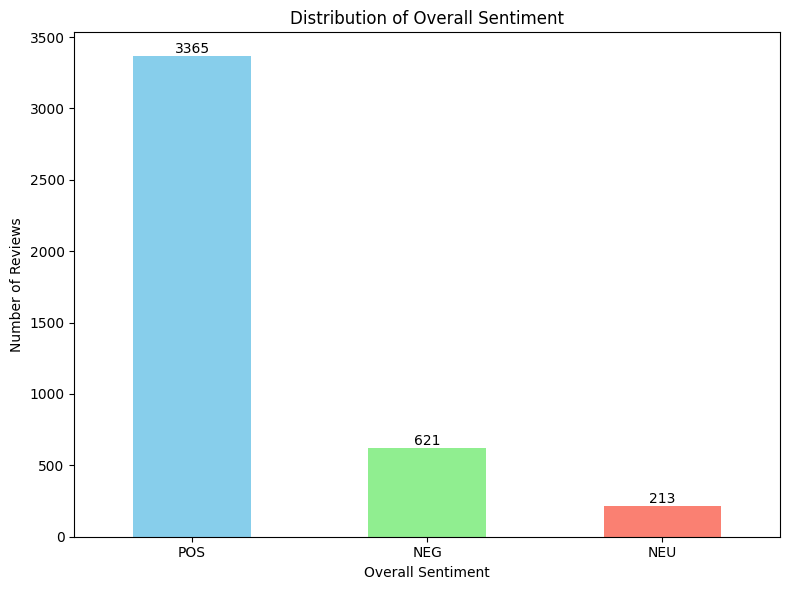

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = df['overall_sentiment'].value_counts()
plt.figure(figsize=(8, 6))
ax = sentiment_counts.plot(kind='bar', color=['skyblue', 'lightgreen', 'salmon'])
plt.xlabel('Overall Sentiment')
plt.ylabel('Number of Reviews')
plt.title('Distribution of Overall Sentiment')
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')
plt.tight_layout()
plt.show()

In [ ]:
def classify_confidence(score):
    """
    Classifies the sentiment confidence level based on the score.

    Args:
        score (float): The sentiment score.

    Returns:
        str: The confidence level ('Rất chắc chắn', 'Có thể đúng', or 'Mơ hồ / đáng nghi ngờ').
    """
    if score is None:
        return 'Mơ hồ / đáng nghi ngờ'
    elif score > 0.8:
        return 'Rất chắc chắn'
    elif 0.5 <= score <= 0.8:
        return 'Có thể đúng'
    else:
        return 'Mơ hồ / đáng nghi ngờ'
df['confidence_level'] = df['sentiment_score'].apply(classify_confidence)

display(df[['sentiment_score', 'confidence_level']].head())

,sentiment_score,confidence_level
0,0.998214,Rất chắc chắn
1,0.963574,Rất chắc chắn
2,0.999600,Rất chắc chắn
3,0.999610,Rất chắc chắn
4,0.996544,Rất chắc chắn


In [ ]:
confidence_counts = df['confidence_level'].value_counts()
print("Số lượng dự đoán theo mức độ chắc chắn:")
print(confidence_counts)

Số lượng dự đoán theo mức độ chắc chắn:
confidence_level
Rất chắc chắn            3950
Có thể đúng               231
Mơ hồ / đáng nghi ngờ      18
Name: count, dtype: int64


In [ ]:
df['review_length'] = df['cleaned_review'].astype(str).apply(len)
display(df[['cleaned_review', 'review_length']].head())

,cleaned_review,review_length
0,trung tâm thương mại lớn \nđầy đủ mọi dịch vụ ...,1179
1,ưu điểm\n sức chứa khách lớn khủng khiếp\n diệ...,683
2,không gian rộng rãi sang trọng mát mẻ\ncó nhiề...,126
3,cảnh quan bố trí hài hoà không gian xanh tạo c...,254
4,là 1 con dân hà đông đã quen với aeon xứ sư tử...,634


In [ ]:
# Determine quantiles for review length
quantiles = df['review_length'].quantile([0.33, 0.66])
short_threshold = quantiles.iloc[0]
long_threshold = quantiles.iloc[1]

# Create a new column for review length categories
def categorize_review_length(length):
    if length <= short_threshold:
        return 'Ngắn'
    elif length <= long_threshold:
        return 'Trung bình'
    else:
        return 'Dài'

df['review_length_category'] = df['review_length'].apply(categorize_review_length)

sentiment_by_length = df.groupby(['review_length_category', 'overall_sentiment']).size().unstack(fill_value=0)
print("Số lượng review theo nhóm độ dài và cảm xúc:")
display(sentiment_by_length)

Số lượng review theo nhóm độ dài và cảm xúc:


overall_sentiment,NEG,NEU,POS
review_length_category,,,
Dài,332,49,1034
Ngắn,123,85,1200
Trung bình,166,79,1131


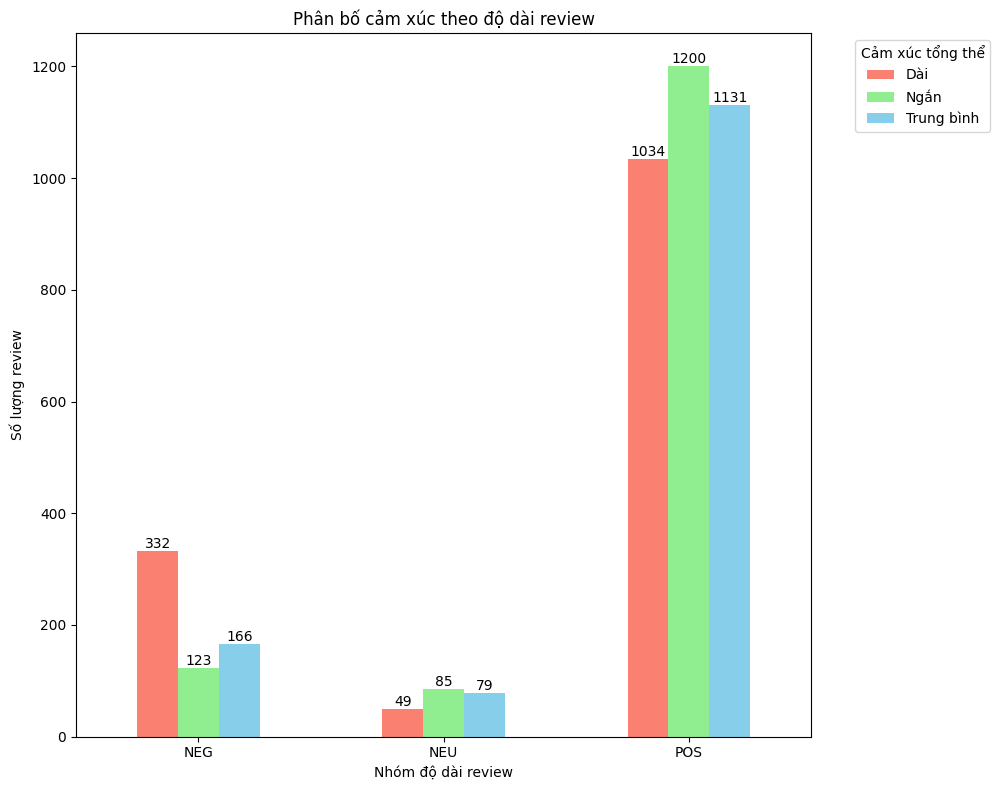

In [ ]:
import matplotlib.pyplot as plt

# Transpose the sentiment_by_length DataFrame for the desired orientation
sentiment_by_length_transposed = sentiment_by_length.T

# Create a grouped bar chart with transposed data
ax = sentiment_by_length_transposed.plot(kind='bar', figsize=(12, 8), color=['salmon', 'lightgreen', 'skyblue'])

# Add labels and title
plt.xlabel('Nhóm độ dài review')
plt.ylabel('Số lượng review')
plt.title('Phân bố cảm xúc theo độ dài review')
plt.xticks(rotation=0) # Keep labels horizontal for better readability

# Add data labels
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')


# Add a legend
plt.legend(title='Cảm xúc tổng thể', bbox_to_anchor=(1.05, 1), loc='upper left')

# Display the chart
plt.tight_layout(rect=[0, 0, 0.85, 1]) # Adjust layout to make space for the legend
plt.show()

In [ ]:
grouped_data = df.groupby(['confidence_level', 'overall_sentiment']).size().unstack(fill_value=0)

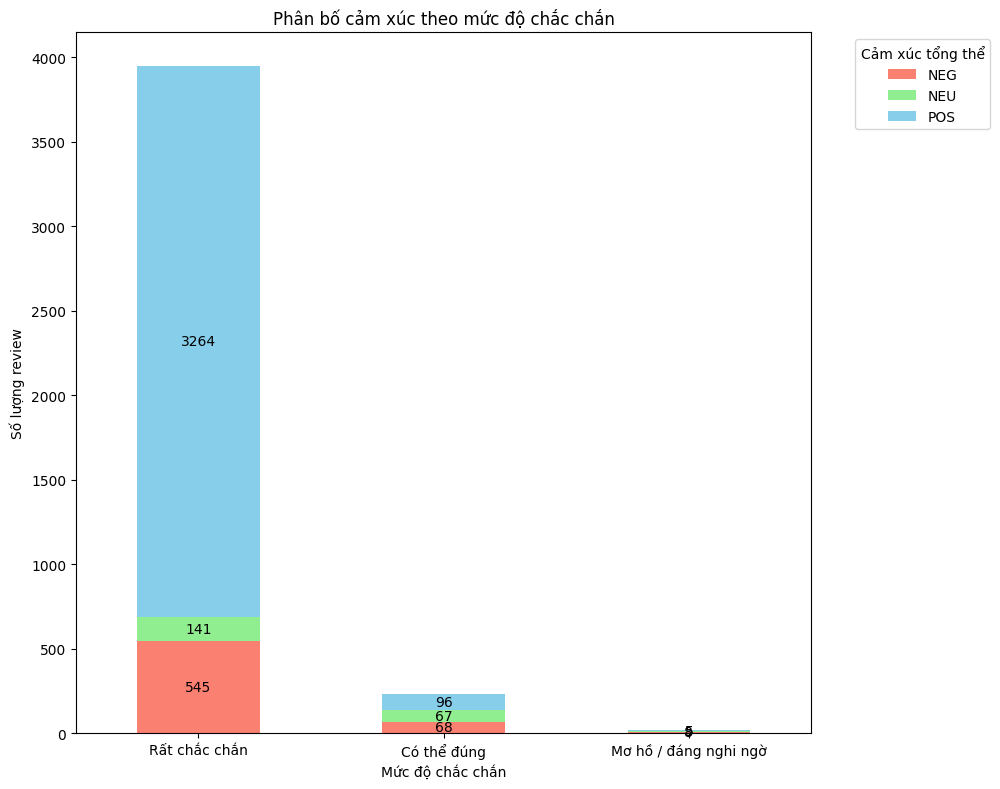

In [ ]:
import matplotlib.pyplot as plt

# Define the desired order of confidence levels
confidence_order = ['Rất chắc chắn', 'Có thể đúng', 'Mơ hồ / đáng nghi ngờ']

# Reindex the grouped_data DataFrame to follow the desired order
grouped_data = grouped_data.reindex(confidence_order)

# Create a stacked bar chart
ax = grouped_data.plot(kind='bar', stacked=True, figsize=(12, 8), color=['salmon', 'lightgreen', 'skyblue'])

# Add labels and title
plt.xlabel('Mức độ chắc chắn')
plt.ylabel('Số lượng review')
plt.title('Phân bố cảm xúc theo mức độ chắc chắn')
plt.xticks(rotation=0) # Keep labels horizontal for better readability

# Add data labels to each section of the stacked bars, except for "Mơ hồ / đáng nghi ngờ"
for i, container in enumerate(ax.containers):
    # Check if the current bar corresponds to "Mơ hồ / đáng nghi ngờ" and skip adding labels
    if grouped_data.columns[i] != 'Mơ hồ / đáng nghi ngờ':
        ax.bar_label(container, fmt='%d', label_type='center')


# Add a legend
plt.legend(title='Cảm xúc tổng thể', bbox_to_anchor=(1.05, 1), loc='upper left')

# Display the chart
plt.tight_layout(rect=[0, 0, 0.85, 1]) # Adjust layout to make space for the legend
plt.show()